# Solutions to the exercises of Chapter 13

Sample solutions for [Chapter 13, Polymer dynamics](../../notebooks/part3_soft_materials/13_polymer_dynamics.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.linalg import expm

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()
k_spring = 3.0

def laplacian(N):
    return np.diag(np.r_[1.0, 2.0 * np.ones(N - 2), 1.0]) - np.eye(N, k=1) - np.eye(N, k=-1)

## Exercise 1. The Rouse viscosity

From Eq. (13.7), $\eta - \eta_s = \nu k_BT\sum_p1/2\lambda_p$. With $\lambda_p \simeq 3\pi^2k_BTp^2/\zeta N^2b^2$,

$$ \eta - \eta_s \simeq \nu k_BT\,\frac{\zeta N^2b^2}{6\pi^2k_BT}\sum_{p=1}^\infty\frac{1}{p^2} = \frac{\nu\zeta N^2b^2}{36} . $$

In [2]:
print("    N     sum 1/(2 lambda_p) / N^2     (1/36 = 0.027778)")
for N in (4, 16, 64, 256, 1024):
    rates = 4 * k_spring * np.sin(np.arange(1, N) * np.pi / (2 * N)) ** 2
    print(f"  {N:5d}          {np.sum(1 / (2 * rates)) / N**2:.6f}")

    N     sum 1/(2 lambda_p) / N^2     (1/36 = 0.027778)
      4          0.026042
     16          0.027669
     64          0.027771
    256          0.027777
   1024          0.027778


The sum approaches $1/36$ from below, within 0.4 % already for 16 beads. At fixed mass
concentration the number of chains per volume is $\nu \propto 1/N$, so $\eta - \eta_s \propto N$: in the
Rouse model the viscosity of a solution, or of a melt of short chains, grows in
proportion to the molar mass. (Melts of long chains, which entangle, follow $N^{3.4}$.)

## Exercise 2. The middle bead

In the continuum limit a bead deep inside a long chain feels a chain infinite on both
sides. Its displacement is a sum over Fourier modes of wave number $q$ along the chain,
each relaxing at the rate $(k/\zeta)q^2$ with the equilibrium amplitude $k_BT/kq^2$:

$$ g(t) = 3\cdot2\int_{-\infty}^\infty\frac{dq}{2\pi}\,\frac{k_BT}{kq^2}\Big(1 - e^{-kq^2t/\zeta}\Big) = \frac{6k_BT}{k}\Big(\frac{kt}{\pi\zeta}\Big)^{1/2} = \Big(\frac{12k_BTb^2t}{\pi\zeta}\Big)^{1/2} . $$

In [3]:
N = 256
L = laplacian(N)
cov = np.linalg.pinv(k_spring * L)
m = N // 2
times = np.logspace(-1, 4.5, 23)
rates = np.linalg.eigvalsh(k_spring * L)
print(f"N = {N}: Rouse time {1 / rates[1]:.0f}")
print("        t       g exact      (12 t/pi)^(1/2)    ratio")
for t in times[::2]:
    g = 3 * (2 * cov[m, m] - 2 * (expm(-k_spring * L * t) @ cov)[m, m]) + 6 * t / N
    print(f"  {t:9.2f}   {g:9.3f}      {math.sqrt(12 * t / math.pi):9.3f}       {g / math.sqrt(12 * t / math.pi):.4f}")

N = 256: Rouse time 2213
        t       g exact      (12 t/pi)^(1/2)    ratio
       0.10       0.463          0.618       0.7494
       0.32       1.016          1.099       0.9242
       1.00       1.912          1.954       0.9784
       3.16       3.454          3.475       0.9937
      10.00       6.167          6.180       0.9978
      31.62      10.978         10.990       0.9989


     100.00      19.563         19.544       1.0010
     316.23      35.123         34.755       1.0106


    1000.00      61.809         61.804       1.0001
    3162.28     116.915        109.905       1.0638
   10000.00     264.771        195.441       1.3547
   31622.78     790.073        347.549       2.2733


Between the time of a bead (about 1) and the Rouse time (about $2\times10^3$ here) the
exact result follows the $t^{1/2}$ law within about 1 %; beyond the Rouse time the middle bead
moves with the chain as a whole.

## Exercise 3. Rouse or Zimm?

A coil of size $R = bN^{1/2}$ with the Stokes friction $6\pi\eta_sR$ diffuses with $D_Z = k_BT/6\pi\eta_sR$. The
time to move its own size is

$$ \tau_Z \approx \frac{R^2}{D_Z} = \frac{6\pi\eta_sR^3}{k_BT} = \frac{6\pi\eta_sb^3}{k_BT}\,N^{3/2} . $$

The Rouse time with $\zeta = 6\pi\eta_sb$ is $\tau_1 = 2\eta_sb^3N^2/\pi k_BT$, so

$$ \frac{\tau_1}{\tau_Z} \approx \frac{N^{1/2}}{3\pi^2} . $$

In [4]:
for N in (100, 1000, 1e4, 1e5, 1e6):
    print(f"N = {N:8.0f}:  tau_Rouse / tau_Zimm = {math.sqrt(N) / (3 * math.pi**2):.2f}")
print(f"factor of ten at N = {(30 * math.pi**2) ** 2:.2e}")

N =      100:  tau_Rouse / tau_Zimm = 0.34
N =     1000:  tau_Rouse / tau_Zimm = 1.07
N =    10000:  tau_Rouse / tau_Zimm = 3.38
N =   100000:  tau_Rouse / tau_Zimm = 10.68
N =  1000000:  tau_Rouse / tau_Zimm = 33.77
factor of ten at N = 8.77e+04


With these crude numbers the Rouse time exceeds the Zimm estimate tenfold only for
$N \approx 9\times10^4$ beads; the numerical prefactors are uncertain, but the ratio grows as $N^{1/2}$.
The point is the scaling. In a dilute solution the solvent inside the coil moves with
it, the coil behaves like a solid sphere, and the relaxation time scales as $R^3 \propto N^{3/2}$
(in a good solvent, $N^{3\nu}$) instead of $N^2$. Experiments on dilute solutions follow Zimm.

## Exercise 4. Hysteresis

With the friction $\zeta_{\rm d}(X) = \zeta S(1 + cx)$, $x = X/X_{\max}$, the Rayleighian of the dumbbell in flow is
$\Phi = \tfrac12\zeta_{\rm d}(X)(\dot X - \dot\varepsilon X)^2$ plus the rate of change of the FENE free energy, and its minimum
gives $\zeta_{\rm d}(X)(\dot X - \dot\varepsilon X) = -f(X/(N - 1))$. In a steady state, with Eq. (13.10),

$$ \dot\varepsilon = \frac{\lambda_{\rm trial}}{(1 + cx)(1 - x^2)} . $$

Without the extra friction ($c = 0$) this rises monotonically from $\lambda_{\rm trial}$: one stretched
state for each flow rate above the threshold. With $c > 0$ the denominator first grows,
reaches a maximum at $x^* = [(1 + 3c^2)^{1/2} - 1]/3c$, then falls to zero. For flow rates
between $\lambda_{\rm trial}/[(1 + cx^*)(1 - x^{*2})]$ and $\lambda_{\rm trial}$ there are two steady states besides the
coil: an unstable one at small $x$ (a barrier) and a stable stretched one. The coil
is stable below $\lambda_{\rm trial}$, so in this window the chain is coiled or stretched
depending on its history.

c = 1.0: bistable for 0.979 < Wi < 1.160  (x* = 0.333)
c = 3.0: bistable for 0.618 < Wi < 1.160  (x* = 0.477)
c = 8.0: bistable for 0.308 < Wi < 1.160  (x* = 0.537)
c = 3.0, Wi = 0.9: from x = 0.02 the dumbbell ends at x = 0.0001
c = 3.0, Wi = 0.9: from x = 0.9 the dumbbell ends at x = 0.7846


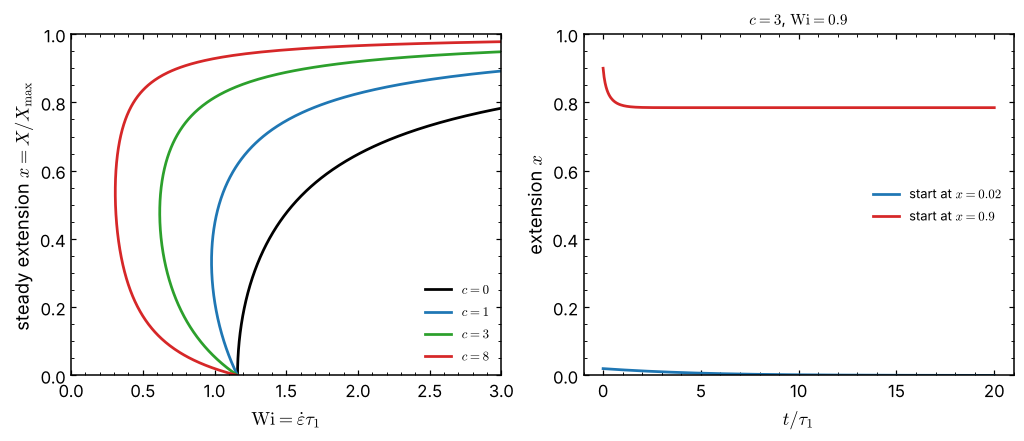

In [5]:
N, Q = 20, 10.0
lam1 = 4 * k_spring * np.sin(np.pi / (2 * N)) ** 2
S = N * (N + 1) / (12 * (N - 1))
lam_trial = k_spring / (S * (N - 1))
xs = np.linspace(0, 0.995, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
for c, color in zip((0.0, 1.0, 3.0, 8.0), ("k", "C0", "C2", "C3")):
    wi = lam_trial / ((1 + c * xs) * (1 - xs**2)) / lam1
    ax1.plot(wi, xs, color=color, lw=1.8, label=f"$c = {c:g}$")
    if c > 0:
        xstar = (math.sqrt(1 + 3 * c * c) - 1) / (3 * c)
        low = lam_trial / ((1 + c * xstar) * (1 - xstar**2)) / lam1
        print(f"c = {c:3.1f}: bistable for {low:.3f} < Wi < {lam_trial / lam1:.3f}  (x* = {xstar:.3f})")
ax1.set_xlabel(r"$\mathrm{Wi} = \dot\varepsilon\tau_1$"); ax1.set_ylabel(r"steady extension $x = X/X_{\max}$")
ax1.set_xlim(0, 3); ax1.set_ylim(0, 1); ax1.legend(loc="lower right", fontsize=8.5)

c, wi_run = 3.0, 0.9
rate = wi_run * lam1
def rhs(t, X):
    x = X[0] / ((N - 1) * Q)
    force = k_spring * (X[0] / (N - 1)) / (1 - x * x)
    return [rate * X[0] - force / (S * (1 + c * x))]
t = np.linspace(0, 20, 400) / lam1
for x0, style in ((0.02, "C0-"), (0.9, "C3-")):
    sol = solve_ivp(rhs, (0, t[-1]), [x0 * (N - 1) * Q], t_eval=t, rtol=1e-9)
    ax2.plot(t * lam1, sol.y[0] / ((N - 1) * Q), style, lw=1.8, label=f"start at $x = {x0:g}$")
    print(f"c = {c}, Wi = {wi_run}: from x = {x0} the dumbbell ends at x = {sol.y[0][-1] / ((N - 1) * Q):.4f}")
ax2.set_xlabel(r"$t/\tau_1$"); ax2.set_ylabel("extension $x$"); ax2.set_ylim(0, 1)
ax2.legend(loc="center right", fontsize=8.5); ax2.set_title(r"$c = 3$, $\mathrm{Wi} = 0.9$", fontsize=10)
plt.show()

**Figure S13.1.** **(a)** Steady extension of a dumbbell whose friction grows with its
extension. Where a curve bends back, the middle branch is unstable and two stable
states coexist. **(b)** The same flow rate leaves a coiled dumbbell coiled and keeps a
stretched one stretched.

The window of bistability widens with $c$: for $c = 1$ it spans Wi from 0.98 to 1.16,
for $c = 3$ from 0.62, and for $c = 8$ from 0.31. This is the mechanism de Gennes proposed: a coil shields its
inner beads from the flow, a stretched chain does not, so stretching increases the
pull of the flow and reinforces itself. The Rouse model, whose friction does not
depend on the conformation, cannot show it.